# Notebook 10: Pairs Trading in Two Simulated Order Books

**References:** Engle, R. F. and Granger, C. W. J. (1987). Co-integration and error correction: representation, estimation, and testing. *Econometrica*, 55(2), 251–276. Gatev, E., Goetzmann, W. N. and Rouwenhorst, K. G. (2006). Pairs trading: performance of a relative-value arbitrage rule. *Review of Financial Studies*, 19(3), 797–827. Avellaneda, M. and Lee, J.-H. (2010). Statistical arbitrage in the US equities market. *Quantitative Finance*, 10(7), 761–782.

A pairs trade bets that two prices which usually move together come back together after they drift apart: sell the dear one, buy the cheap one, and unwind when the gap closes. It needs a gap that mean-reverts (the two prices are cointegrated) and deviations wide enough to pay for crossing two spreads on the way in and two on the way out.

This notebook builds two order books whose gap mean-reverts by construction (`lob/pairs.py`), asks what a trader can learn about the gap from the books alone, and runs a pairs trading rule in them, paying their spreads.

**The model.** Each book's traders place orders around the book's *fair value*: limit orders 1 to 8 ticks either side of it, market orders and cancellations, as in the zero-intelligence model of notebook 03 but anchored to a value instead of the opposite best quote. A new limit order priced across a stale quote trades on arrival, so a book reprices as its fair value moves. The fair values share a common factor $X$, a random walk, and each has a part of its own, $U$:

$$F_A = X + U_A, \qquad F_B = \ell_B + \beta\,(X - X_0) + U_B, \qquad dU = -\kappa\,U\,dt + \sigma_u\,dW + \lambda\,dQ,$$

where $\kappa = \ln 2 / \text{half-life}$ and $dQ$ is the net lots taken by market orders in the book (price impact $\lambda$ a lot, from anyone). The gap $G = U_B - \beta\,U_A$ then mean-reverts with that half-life. Without a half-life ($\kappa = 0$) the own parts wander, impact is permanent, and the gap wanders too; an **arbitrageur** who buys the cheap book and sells the dear one when the mids are 2 ticks apart then brings it back through its own impact.

A random walk has no floor, but a price does: orders stop at one tick. So a fair value stops at 10 ticks, the lowest at which orders up to 8 ticks from it all stay above that. A fall that would take one lower is cut short by pushing $X$ back up, just as far as needed, which moves both books together and leaves the gap alone. Starting from a level of 100, some of the longer runs below reach it, most of all where the own parts wander.

In [1]:
import math
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from IPython.display import display
from statsmodels.tsa.stattools import adfuller
from quant_plots import Backtest, scorecard, signal_chart

from lob.analysis.plotting import set_style
from lob.pairs import A, B, Arbitrageur, FairValues, PairMarket, PairsTrader

set_style()

SEEDS = range(1, 9)
HALF_LIFE = 50.0     # time units
OWN_VOL = 0.8        # each book's own part, ticks per square root of a time unit: a gap sd of about 6.8 ticks


def market(seed, half_life=HALF_LIFE, own_volatility=OWN_VOL, arbitrageur=False, traders=()):
    return PairMarket(FairValues(half_life=half_life, own_volatility=own_volatility),
                      arbitrageur=Arbitrageur() if arbitrageur else None, seed=seed, traders=traders)


def half_life(x, lag=1):
    # From the lag-`lag` autocorrelation of a series sampled once a time unit.
    x = np.asarray(x) - np.mean(x)
    phi = np.corrcoef(x[:-lag], x[lag:])[0, 1]
    return -lag * math.log(2) / math.log(phi) if 0 < phi < 1 else np.inf

## 1. Two Books, One Gap

One run of 4,000 time units with a half-life of 50. The top panel shows both books' mids and their fair values; the bottom panel shows the gap a trader sees, $\text{mid}_B - \ell_B - \beta(\text{mid}_A - X_0)$, against the true gap $G$.

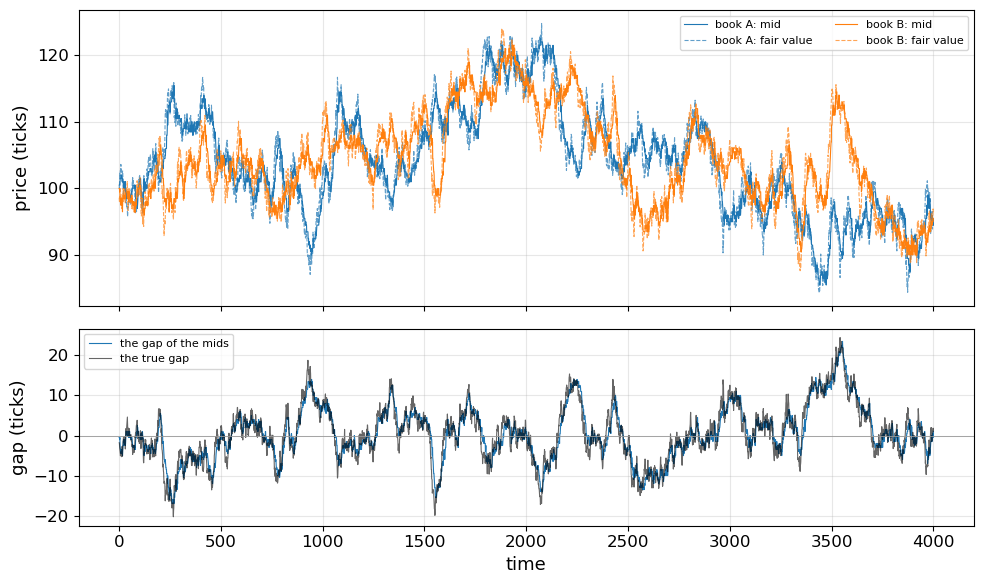

Each book's mid stays within 1.7 (A) and 1.7 (B) ticks of its fair value (root mean square), with a mean spread of 1.9 ticks.
The gap of the mids follows the true gap (correlation 0.94), best 4 time units late (0.96): the books lag their fair values.


In [2]:
m = market(1)
d = m.run(4000)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
for k, color in (('a', 'C0'), ('b', 'C1')):
    top.plot(d.time, d[f'mid_{k}'], color=color, lw=0.8, label=f'book {k.upper()}: mid')
    top.plot(d.time, d[f'fair_{k}'], color=color, lw=0.8, ls='--', alpha=0.7, label=f'book {k.upper()}: fair value')
top.set_ylabel('price (ticks)')
top.legend(ncol=2, fontsize=8)
bottom.plot(d.time, d.gap, lw=0.8, label='the gap of the mids')
bottom.plot(d.time, d.true_gap, lw=0.8, color='k', alpha=0.6, label='the true gap')
bottom.axhline(0, color='0.6', lw=0.6)
bottom.set_ylabel('gap (ticks)')
bottom.set_xlabel('time')
bottom.legend(fontsize=8)
plt.tight_layout()
plt.show()

track = {k: float(np.sqrt(np.mean((d[f'mid_{k}'] - d[f'fair_{k}']) ** 2))) for k in 'ab'}
lags = {k: float(np.corrcoef(d.gap[k:], d.true_gap[:len(d) - k])[0, 1]) for k in range(0, 11)}
best = max(lags, key=lags.get)
print(f"Each book's mid stays within {track['a']:.1f} (A) and {track['b']:.1f} (B) ticks of its fair value "
      f"(root mean square), with a mean spread of {d.spread_a.mean():.1f} ticks.")
print(f"The gap of the mids follows the true gap (correlation {lags[0]:.2f}), best {best} time units late "
      f"({lags[best]:.2f}): the books lag their fair values.")

## 2. Is It a Pair? Cointegration

The Engle–Granger test regresses B's mid on A's by least squares and asks whether the residual has a unit root (an augmented Dickey–Fuller test; a small p-value says it does not, so the prices are cointegrated). Three settings, 8 seeds each, 4,000 time units: the fair values' gap mean-reverts (half-life 50); it wanders (no half-life); it wanders but an arbitrageur trades it back.

In [3]:
SETTINGS = {'reverting (half-life 50)': dict(half_life=HALF_LIFE), 'wandering': dict(half_life=None),
            'wandering, with the arbitrageur': dict(half_life=None, arbitrageur=True)}


def engle_granger(setting, seed, units=4000):
    d = market(seed, **SETTINGS[setting]).run(units).dropna(subset=['mid_a', 'mid_b'])
    beta, alpha = np.polyfit(d.mid_a, d.mid_b, 1)
    p = adfuller((d.mid_b - alpha - beta * d.mid_a).to_numpy(), autolag='AIC')[1]
    return {'setting': setting, 'seed': seed, 'beta': beta, 'p': p}


eg = pd.DataFrame(Parallel(n_jobs=-1)(delayed(engle_granger)(s, seed) for s in SETTINGS for seed in SEEDS))
table = eg.groupby('setting', sort=False).agg(hedge_ratio=('beta', 'median'), p_value=('p', 'median'),
                                              cointegrated=('p', lambda p: f'{(p < 0.05).sum()} of {len(p)}'))
print(table.to_string(float_format=lambda v: f'{v:.3g}'))

                                 hedge_ratio  p_value cointegrated
setting                                                           
reverting (half-life 50)               0.717  0.00351       8 of 8
wandering                              0.113    0.247       0 of 8
wandering, with the arbitrageur        0.978 1.92e-16       8 of 8


The test tells the settings apart. The hedge ratio is another matter: the true $\beta$ is 1, but least squares on a short sample puts it lower. B's mid is regressed on A's, and A's mid moves with the common factor, by a little over a short sample, *and* with A's own part and the book's noise: errors in the regressor attenuate the slope toward zero. Over longer samples the common factor travels further and the estimate approaches 1.

In [4]:
def hedge_ratio(seed, units):
    d = market(seed).run(units, every=4.0).dropna(subset=['mid_a', 'mid_b'])
    return units, seed, np.polyfit(d.mid_a, d.mid_b, 1)[0]


hr = pd.DataFrame(Parallel(n_jobs=-1)(delayed(hedge_ratio)(seed, units) for units in (4_000, 16_000, 64_000)
                                      for seed in range(1, 5)), columns=['units', 'seed', 'beta'])
for units, group in hr.groupby('units'):
    ratios = ', '.join(f'{b:.2f}' for b in group.beta)
    print(f"{units:,} time units: hedge ratios {ratios} (median {group.beta.median():.2f})")

4,000 time units: hedge ratios 0.52, 0.94, 0.78, 0.89 (median 0.83)
16,000 time units: hedge ratios 0.84, 0.94, 0.98, 0.89 (median 0.92)
64,000 time units: hedge ratios 0.98, 0.99, 0.97, 0.98 (median 0.98)


## 3. How Fast Does It Revert?

A pairs trader needs the half-life to choose how long a window to measure the gap over. Estimated from the lag-$k$ autocorrelation of the gap (sampled once a time unit), over 8,000 time units and 8 seeds, from the true gap and from the gap a trader sees:

In [5]:
def half_lives(seed):
    d = market(seed).run(8000)
    return [(seed, lag, series, half_life(d[col], lag)) for lag in (1, 5, 20, 50)
            for series, col in (('the true gap', 'true_gap'), ('the gap of the mids', 'gap'))]


hl = pd.DataFrame([row for rows in Parallel(n_jobs=-1)(delayed(half_lives)(seed) for seed in SEEDS) for row in rows],
                  columns=['seed', 'lag', 'series', 'half_life'])
print(hl.pivot_table(index='lag', columns='series', values='half_life', aggfunc='median').round(1).to_string())

series  the gap of the mids  the true gap
lag                                      
1                     106.2          50.2
5                     120.8          49.9
20                     89.7          53.2
50                     70.7          56.5


The true gap gives the half-life it was made with at every lag. The gap of the mids reverts more slowly, most at short lags: the books follow their fair values with a delay (section 1), which smooths the gap, and the smoothing fades at longer lags. A trader who read the half-life off the mids at short lags would think the gap slower than it is.

## 4. A Pairs Trading Rule, in the Books

`PairsTrader` takes the gap it sees, $\text{mid}_B - \text{hedge} \times \text{mid}_A$, every time unit, and its z-score against the last 400 (eight half-lives). Above 2 it sells 5 lots of B and buys 5 of A (short the gap); below −2 the reverse; it goes flat when the z-score comes back to 0. It trades with market orders in both books, which move them as anyone's do. Eight seeds of 20,000 time units each; P&L is in ticks times lots, at the mids at the end.

In [6]:
def pairs_run(seed, window=400, units=20_000, every=20.0, record=False, **settings):
    trader = PairsTrader(window=window, record=record)
    m = market(seed, traders=(trader,), **settings)
    d = m.run(units, every=every)
    return trader, m, d


def summary(seed, **kwargs):
    trader, m, _ = pairs_run(seed, **kwargs)
    pnl = trader.value(m.mark(A), m.mark(B))
    return {'seed': seed, 'P&L': pnl, 'before costs': pnl + trader.spread_paid, 'crossing cost': trader.spread_paid,
            'entries': trader.entries, 'lots': trader.lots, 'cost a lot': trader.spread_paid / trader.lots}


runs = pd.DataFrame(Parallel(n_jobs=-1)(delayed(summary)(seed) for seed in SEEDS)).set_index('seed')
print(runs.round(2).to_string())
mean, half = runs['P&L'].mean(), 1.96 * runs['P&L'].std() / math.sqrt(len(runs))
share = runs['crossing cost'].mean() / runs['before costs'].mean()
print(f"\nP&L {mean:+.0f} (95% interval {mean - half:+.0f} to {mean + half:+.0f}), positive in "
      f"{(runs['P&L'] > 0).sum()} of {len(runs)} runs; before costs {runs['before costs'].mean():+.0f}: crossing the "
      f"spreads took {share:.0%} of it, {runs['cost a lot'].mean():.2f} ticks a lot.")

        P&L  before costs  crossing cost  entries  lots  cost a lot
seed                                                               
1     502.0        2372.5         1870.5       76  1520        1.23
2     464.0        2305.0         1841.0       73  1460        1.26
3     348.0        2167.5         1819.5       71  1420        1.28
4     152.5        1667.5         1515.0       64  1270        1.19
5     599.0        2177.5         1578.5       66  1320        1.20
6     337.0        1867.5         1530.5       65  1290        1.19
7     609.0        2320.0         1711.0       69  1380        1.24
8     617.5        2445.0         1827.5       74  1470        1.24

P&L +454 (95% interval +339 to +568), positive in 8 of 8 runs; before costs +2165: crossing the spreads took 79% of it, 1.23 ticks a lot.


**The scorecard and the signal chart.** `quant_plots` reads a daily record: the weights held (as fractions of capital) and the assets' returns. Here a card *day* is one of the trader's decisions, one unit of simulation time: the record holds what it held of A and B after each decision, valued at the mids just *before* its orders, against capital of 10,000 (ticks times lots), and the assets' returns are those mids' from one decision to the next. Valued so, the record's P&L before costs is exactly what its fills made before costs. (Valued at mids after its orders, it would also charge the trader its own price impact, which its fills already paid.) Its costs are linear in turnover, and the record's turnover also counts weights drifting with prices, so the cost per unit is set so that, in all, the record pays what crossing the spreads cost.

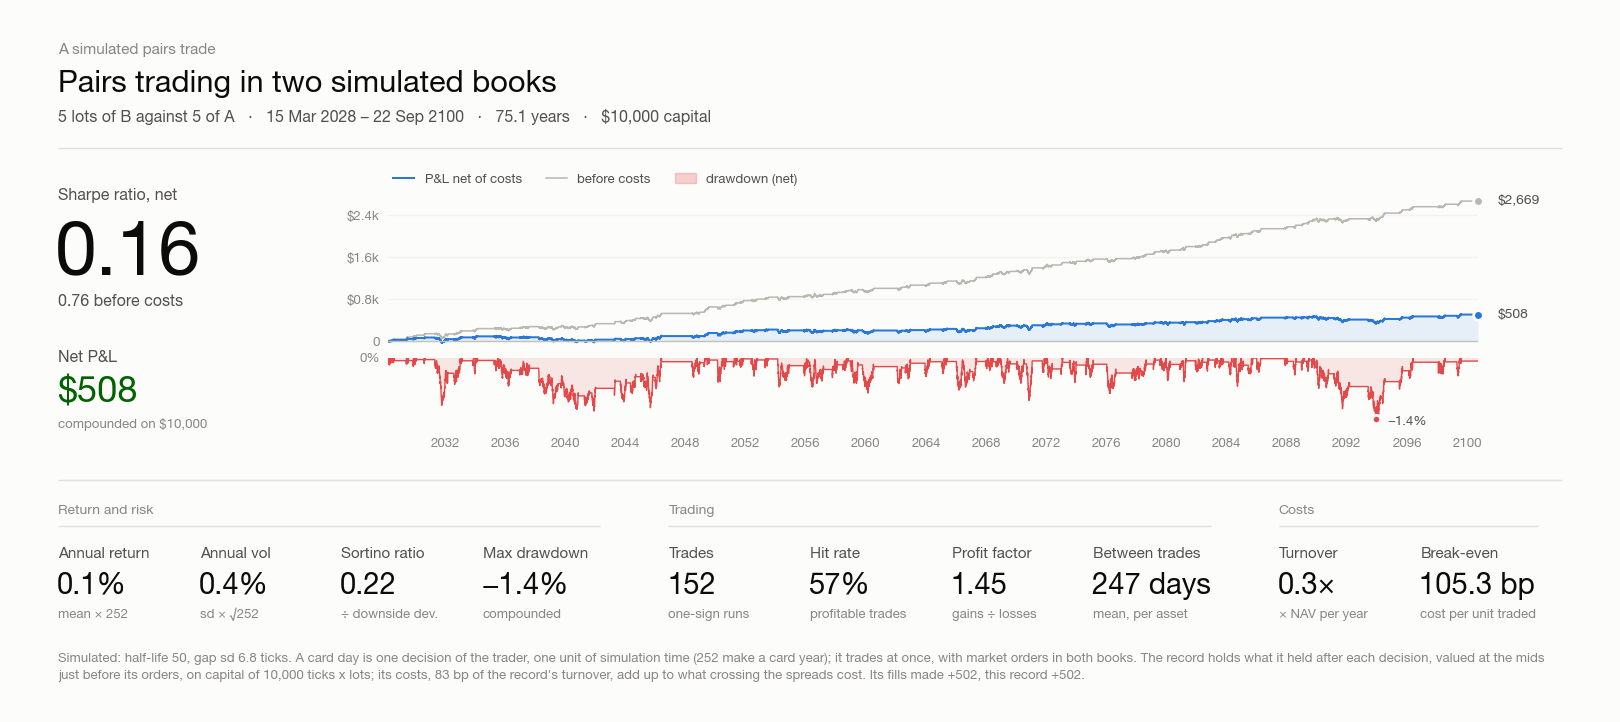

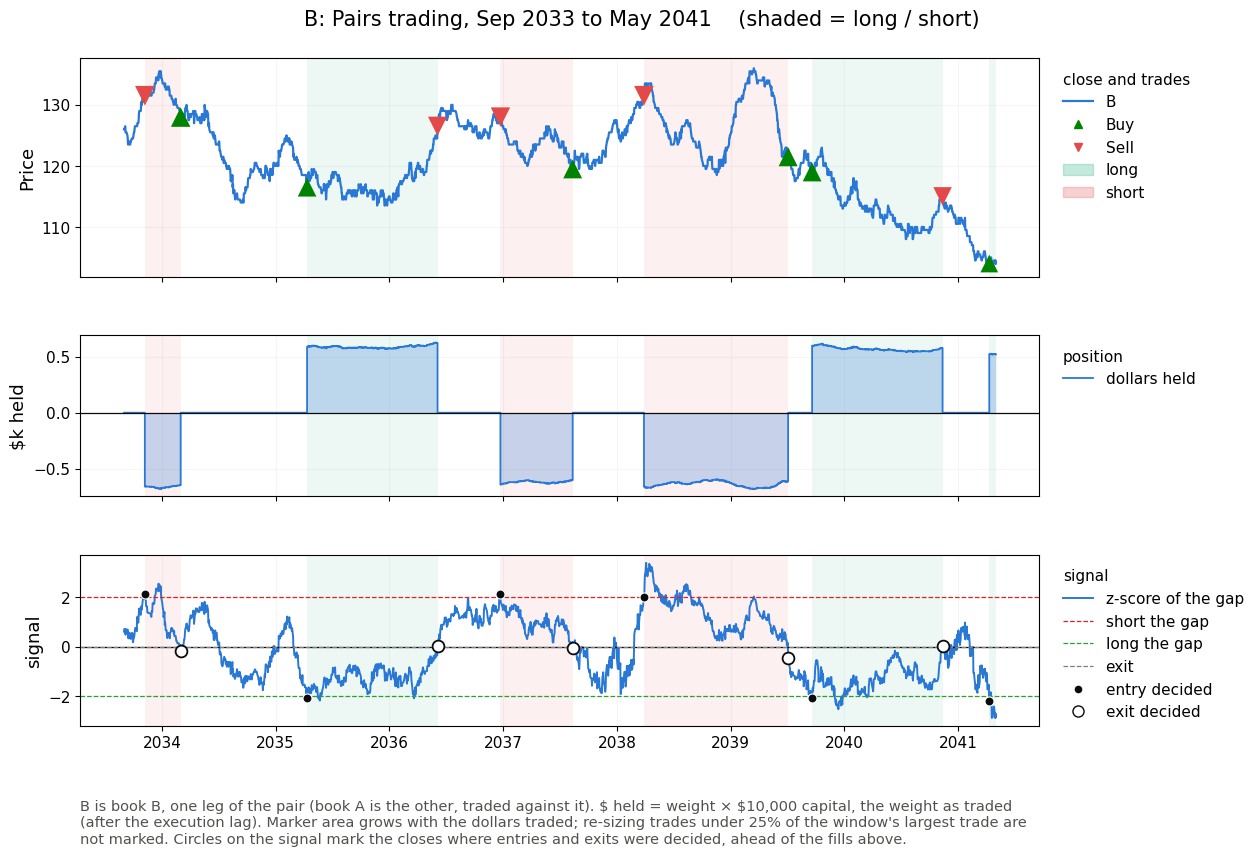

In [7]:
CAPITAL = 10_000.0


def decision_record(trader):
    h = pd.DataFrame(trader.history, columns=['time', 'mid_a', 'mid_b', 'pos_a', 'pos_b', 'z', 'target'])
    days = pd.bdate_range('2026-01-01', periods=len(h))
    mids = pd.DataFrame({'A': h.mid_a.to_numpy(), 'B': h.mid_b.to_numpy()}, index=days)
    held = pd.DataFrame({'A': (h.pos_a * h.mid_a).to_numpy() / CAPITAL, 'B': (h.pos_b * h.mid_b).to_numpy() / CAPITAL},
                        index=days)
    returns = mids.pct_change().fillna(0.0)
    turnover = Backtest(held, returns, cost_bp=0.0).turnover.sum() * CAPITAL
    cost_bp = trader.spread_paid / turnover * 1e4  # the record pays, in all, what crossing the spreads cost
    target = pd.Series(h.target.to_numpy(), index=days)
    change = target.ne(target.shift(1).fillna(0))
    return (Backtest(held, returns, cost_bp=cost_bp), mids, held, pd.Series(h.z.to_numpy(), index=days),
            list(days[change & target.ne(0)]), list(days[change & target.eq(0)]), cost_bp)


def footnote(trader, m, bt, cost_bp, setting):
    fills = trader.value(m.mark(A), m.mark(B))
    return (f"Simulated: {setting}. A card day is one decision of the trader, one unit of simulation time (252 make a "
            f"card year); it trades at once, with market orders in both books. The record holds what it held after "
            f"each decision, valued at the mids just before its orders, on capital of {CAPITAL:,.0f} ticks x lots; its "
            f"costs, {cost_bp:.0f} bp of the record's turnover, add up to what crossing the spreads cost. Its fills "
            f"made {fills:+,.0f}, this record {bt.net.sum() * CAPITAL:+,.0f}.")


trader, m, _ = pairs_run(1, every=1000.0, record=True)
bt, mids, held, z, entries, exits, cost_bp = decision_record(trader)
display(scorecard(bt, 'Pairs trading in two simulated books', detail='5 lots of B against 5 of A', capital=CAPITAL,
                  title='A simulated pairs trade',
                  footnote=footnote(trader, m, bt, cost_bp, 'half-life 50, gap sd 6.8 ticks')))
signal_chart('B', mids['B'], held['B'], z, capital=CAPITAL, strategy='Pairs trading', signal_label='z-score of the gap',
             levels=[(2.0, 'C3', 'short the gap'), (-2.0, 'C2', 'long the gap'), (0.0, 'C7', 'exit')],
             entries=entries, exits=exits, start=mids.index[2000], end=mids.index[4000],
             asset_name='book B, one leg of the pair (book A is the other, traded against it)')
plt.show()

## 5. When Does It Pay?

The rule pays only if the gap's swings are wide against what four crossings of the spread cost, and if it measures the gap over long enough a window. The same rule over a grid: the own parts' volatility (setting the gap's standard deviation) against a window of 100 or 400 decisions, 4 seeds of 10,000 time units each.

In [8]:
def grid_run(own, window, seed):
    row = summary(seed, window=window, units=10_000, every=50.0, own_volatility=own)
    return {'own volatility': own, 'gap sd': round(FairValues(own_volatility=own).gap_sd, 1), 'window': window, **row}


grid = pd.DataFrame(Parallel(n_jobs=-1)(delayed(grid_run)(own, window, seed) for own in (0.4, 0.8, 1.2)
                                        for window in (100, 400) for seed in range(1, 5)))
pays = grid.groupby(['gap sd', 'window']).agg(pnl=('P&L', 'mean'), before_costs=('before costs', 'mean'),
                                               entries=('entries', 'mean'),
                                               positive=('P&L', lambda p: f'{(p > 0).sum()} of {len(p)}'))
print(pays.round(1).to_string())

                  pnl  before_costs  entries positive
gap sd window                                        
3.4    100    -2327.4         848.8    123.2   0 of 4
       400     -204.2         849.4     43.2   0 of 4
6.8    100    -2074.4         370.0     99.0   0 of 4
       400      169.4         969.4     33.0   4 of 4
10.2   100    -2086.1         279.4     91.5   0 of 4
       400      406.6        1166.2     28.5   4 of 4


A short window measures the gap against an average that chases it, so the z-score crosses ±2 often, and the trader pays to cross four spreads each time for little reversion. With a window eight half-lives long it enters a third as often. Then whether it pays depends on the gap: the before-costs P&L grows with the gap's swings while the costs per round trip stay the same.

## 6. When the Reversion Is an Arbitrageur's

Without a half-life the fair values' gap wanders. Alone, the pairs trader then bets on a reversion that does not come; with the arbitrageur in the market (2 ticks of threshold, 5 lots a time), the books' gap stays tight, but the arbitrageur acts first. 4 seeds of 10,000 time units each:

In [9]:
def arb_run(arbitrageur, window, seed):
    row = summary(seed, window=window, units=10_000, every=50.0, half_life=None, arbitrageur=arbitrageur)
    return {'arbitrageur': 'with' if arbitrageur else 'without', 'window': window, **row}


arb = pd.DataFrame(Parallel(n_jobs=-1)(delayed(arb_run)(a, window, seed) for a in (False, True)
                                       for window in (100, 400) for seed in range(1, 5)))
print(arb.groupby(['arbitrageur', 'window']).agg(pnl=('P&L', 'mean'), before_costs=('before costs', 'mean'),
                                                  entries=('entries', 'mean'),
                                                  positive=('P&L', lambda p: f'{(p > 0).sum()} of {len(p)}'))
      .round(1).to_string())

                       pnl  before_costs  entries positive
arbitrageur window                                        
with        100    -2136.6        2855.6    164.8   0 of 4
            400     -422.2        2348.8     93.2   0 of 4
without     100    -3347.2       -1368.1     80.5   0 of 4
            400    -1232.0        -736.2     21.0   0 of 4


With the arbitrageur the gap does revert, and the trader's positions earn before costs, but the arbitrageur trades every deviation past 2 ticks as soon as it appears, and what is left for the z-score rule is too small to pay for its crossings. The scorecard of that case:

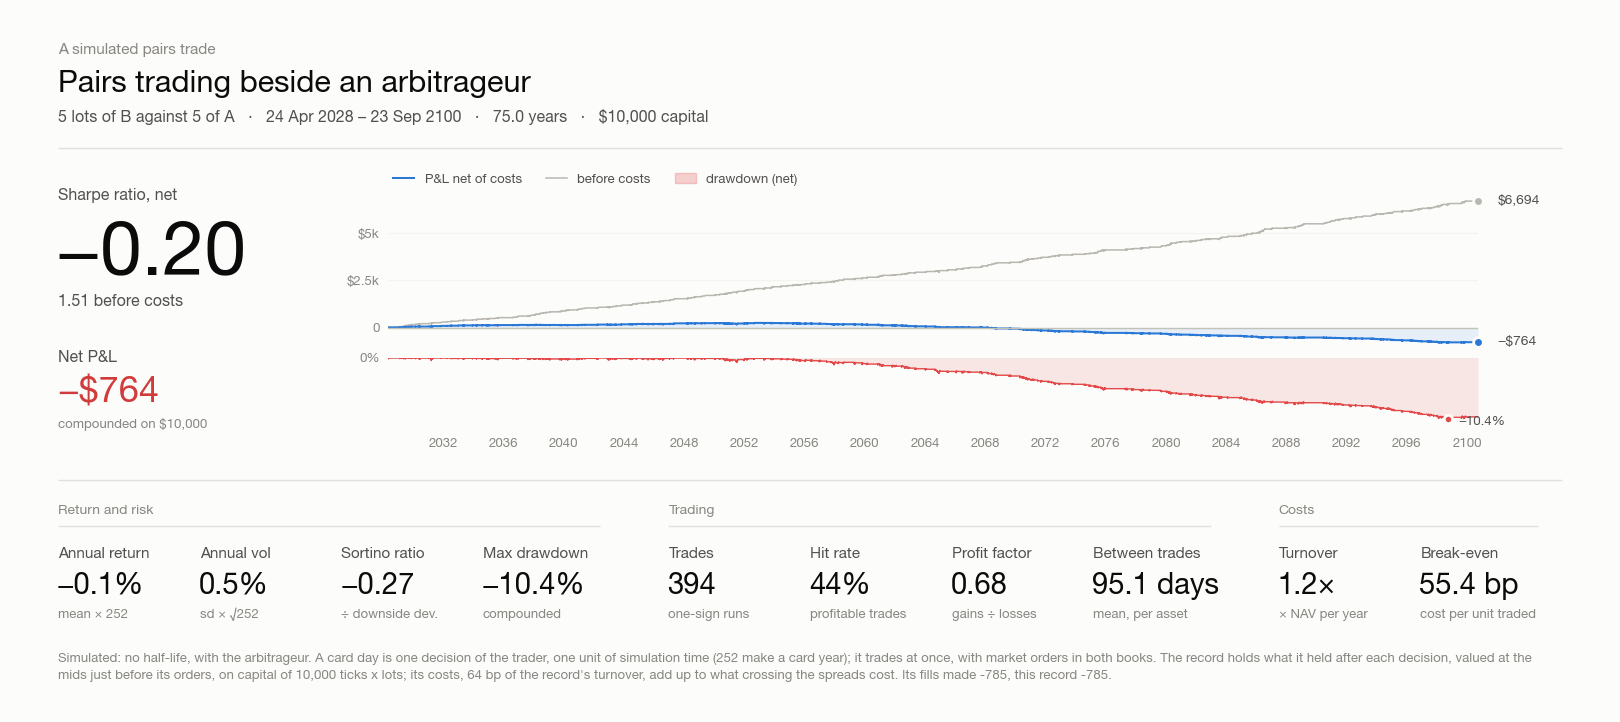

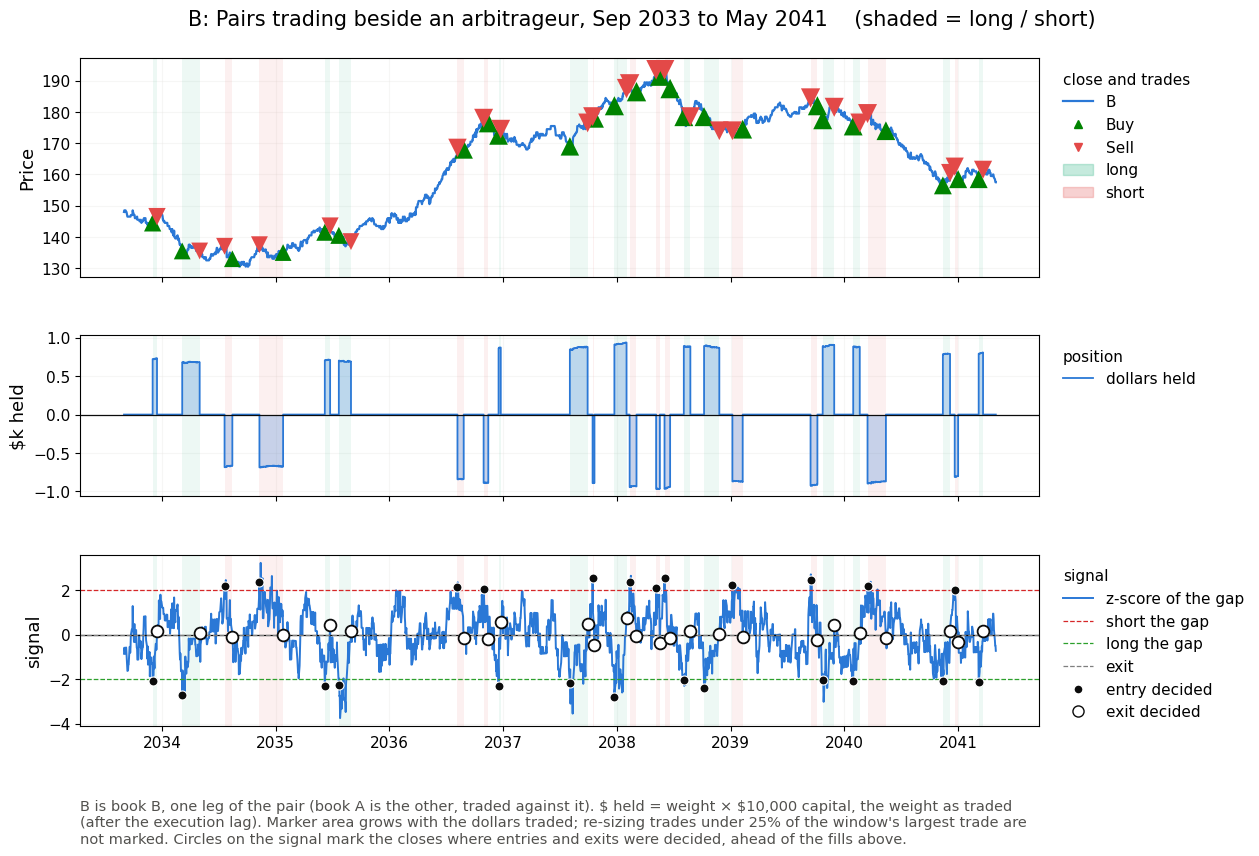

In [10]:
trader, m, _ = pairs_run(1, every=1000.0, record=True, half_life=None, arbitrageur=True)
bt, mids, held, z, entries, exits, cost_bp = decision_record(trader)
display(scorecard(bt, 'Pairs trading beside an arbitrageur', detail='5 lots of B against 5 of A', capital=CAPITAL,
                  title='A simulated pairs trade',
                  footnote=footnote(trader, m, bt, cost_bp, 'no half-life, with the arbitrageur')))
signal_chart('B', mids['B'], held['B'], z, capital=CAPITAL, strategy='Pairs trading beside an arbitrageur',
             signal_label='z-score of the gap', levels=[(2.0, 'C3', 'short the gap'), (-2.0, 'C2', 'long the gap'),
                                                        (0.0, 'C7', 'exit')],
             entries=entries, exits=exits, start=mids.index[2000], end=mids.index[4000],
             asset_name='book B, one leg of the pair (book A is the other, traded against it)')
plt.show()

## 7. Conclusions

In [11]:
reverting = table.loc['reverting (half-life 50)']
wandering = table.loc['wandering']
long_window = pays.xs(400, level='window')
wins = [f"{sd:.1f}" for sd, row in long_window.iterrows() if row.pnl > 0 and row.positive == '4 of 4']
with_arb = arb[(arb.arbitrageur == 'with') & (arb.window == 400)]
print("Conclusions:")
print(f"- The Engle-Granger test finds the reverting books cointegrated in {reverting.cointegrated} seeds and the "
      f"wandering ones in {wandering.cointegrated}; the arbitrageur makes the wandering books cointegrated again "
      f"({table.loc['wandering, with the arbitrageur', 'cointegrated']}).")
print(f"- Least squares underestimates the hedge ratio on short samples (median {reverting.hedge_ratio:.2f} over 4,000 "
      f"time units, against a true 1): errors in A's price attenuate it.")
print(f"- The gap of the mids looks slower than it is: half-lives of "
      f"{hl[(hl.series == 'the gap of the mids') & (hl.lag == 1)].half_life.median():.0f} at lag 1 against "
      f"{hl[(hl.series == 'the true gap') & (hl.lag == 1)].half_life.median():.0f} from the true gap, as the books lag "
      f"their fair values.")
print(f"- The rule pays {mean:+.0f} over 20,000 time units with a half-life of 50 and a gap sd of 6.8 ticks "
      f"({(runs['P&L'] > 0).sum()} of {len(runs)} seeds positive), after crossing costs that take "
      f"{runs['crossing cost'].mean() / runs['before costs'].mean():.0%} of what it earns before them.")
print(f"- It pays only with a long window and a wide enough gap: with a window of 400, a gap sd of "
      f"{', '.join(wins) or 'none'} ticks; with a window of 100, never in these runs.")
print(f"- Beside the arbitrageur it loses ({with_arb['P&L'].mean():+.0f} a run, {(with_arb['P&L'] > 0).sum()} of "
      f"{len(with_arb)} positive), though it would earn {with_arb['before costs'].mean():+.0f} before costs: the "
      f"arbitrageur takes the deviations first.")

Conclusions:
- The Engle-Granger test finds the reverting books cointegrated in 8 of 8 seeds and the wandering ones in 0 of 8; the arbitrageur makes the wandering books cointegrated again (8 of 8).
- Least squares underestimates the hedge ratio on short samples (median 0.72 over 4,000 time units, against a true 1): errors in A's price attenuate it.
- The gap of the mids looks slower than it is: half-lives of 106 at lag 1 against 50 from the true gap, as the books lag their fair values.
- The rule pays +454 over 20,000 time units with a half-life of 50 and a gap sd of 6.8 ticks (8 of 8 seeds positive), after crossing costs that take 79% of what it earns before them.
- It pays only with a long window and a wide enough gap: with a window of 400, a gap sd of 6.8, 10.2 ticks; with a window of 100, never in these runs.
- Beside the arbitrageur it loses (-422 a run, 0 of 4 positive), though it would earn +2349 before costs: the arbitrageur takes the deviations first.


**Limitations.** The traders in both books know nothing beyond their fair values, and the arbitrageur follows a fixed threshold; a real pair's gap can break (the relation that tied the prices ends), which this model never does. Impact is linear and, in the reverting setting, decays with the gap's own half-life. The pairs trader uses the true hedge ratio of 1 rather than an estimate, trades only with market orders, and pays no fees. The scorecard's record is daily in name only: its "days" are the trader's decisions, one time unit each, and its "years" 252 of them.